<a href="https://colab.research.google.com/github/yorgi544/data_acquisition/blob/main/AKUISISI_DATA_AKOMODASI_WISATA_BADUNG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ==========================================
# TUGAS 1
# AKUISISI DATA AKOMODASI WISATA BADUNG
# ==========================================

import os
import json
import csv
import hashlib
import time
import requests
import pandas as pd

from datetime import datetime, timezone, timedelta
from pathlib import Path

NAMA = "Herkulano Yorgi Novriandri Simuk"
NIM = "2501010203"
PROGRAM_STUDI = "Informatika"
INSTITUSI = "INSTIKI"

ROOT = Path("/content/rtm1_2501010203")

# Membuat struktur folder
for folder in [
    "notebooks",
    "data/raw",
    "docs"
]:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

print("PROYEK BERHASIL DIPERSIAPKAN")
print("Nama:", NAMA)
print("NIM:", NIM)
print("Program Studi:", PROGRAM_STUDI)
print("Folder:", ROOT)

PROYEK BERHASIL DIPERSIAPKAN
Nama: Herkulano Yorgi Novriandri Simuk
NIM: 2501010203
Program Studi: Informatika
Folder: /content/rtm1_2501010203


In [ ]:
# ==========================================
# PEMERIKSAAN SUMBER DATA
# ==========================================

SOURCE = "OpenStreetMap"
PUBLISHER = "OpenStreetMap contributors"
ENDPOINT = "https://overpass-api.de/api/interpreter"

# Ganti dengan email kampus kamu yang aktif
EMAIL_KAMPUS = "yorgisimuk@gmail.com"

HEADERS = {
    "User-Agent": (
        "Mahasiswa INSTIKI - Akuisisi Data Badung "
        + EMAIL_KAMPUS
    )
}

print("Sumber:", SOURCE)
print("Penerbit:", PUBLISHER)
print("Endpoint:", ENDPOINT)
print("Lisensi: Open Database License (ODbL)")
print("Atribusi: © OpenStreetMap contributors")

Sumber: OpenStreetMap
Penerbit: OpenStreetMap contributors
Endpoint: https://overpass-api.de/api/interpreter
Lisensi: Open Database License (ODbL)
Atribusi: © OpenStreetMap contributors


In [ ]:
# ==========================================
# AKUISISI DATA OPENSTREETMAP
# WILAYAH KABUPATEN BADUNG
# ==========================================

# Menggunakan standard Overpass QL untuk mencari area Kabupaten Badung
query = """
[out:json][timeout:120];

area["name"="Badung"]["admin_level"="5"]->.searchArea;

(
  nwr["tourism"~"^(hotel|hostel|guest_house|motel|apartment|chalet|camp_site|caravan_site)$"]
  (area.searchArea);
);

out center tags;
"""

print("Menghubungi OpenStreetMap API...")

response = requests.post(
    ENDPOINT,
    data={"data": query},
    headers=HEADERS,
    timeout=150
)

print("Status HTTP:", response.status_code)

response.raise_for_status()

hasil_json = response.json()

print("Pengambilan data berhasil!")
print("Jumlah objek:", len(hasil_json["elements"]))


Menghubungi OpenStreetMap API...
Status HTTP: 200
Pengambilan data berhasil!
Jumlah objek: 3195


In [ ]:
# ==========================================
# MENYIMPAN DATA MENTAH
# ==========================================

waktu_utc = datetime.now(timezone.utc)
tanggal = waktu_utc.strftime("%Y%m%d")

nama_json = f"osm_akomodasi_badung_{tanggal}.json"
nama_csv = f"osm_akomodasi_badung_{tanggal}.csv"

path_json = ROOT / "data/raw" / nama_json
path_csv = ROOT / "data/raw" / nama_csv

# JSON asli disimpan tanpa mengubah respons API
with open(path_json, "w", encoding="utf-8") as file:
    json.dump(
        hasil_json,
        file,
        ensure_ascii=False,
        indent=2
    )

print("Data JSON berhasil disimpan:", nama_json)
print("Ukuran data:", path_json.stat().st_size, "bytes")

Data JSON berhasil disimpan: osm_akomodasi_badung_20261115.json
Ukuran data: 964169 bytes


In [ ]:
# ==========================================
# MEMBUAT DATASET CSV
# ==========================================

data = []

for item in hasil_json["elements"]:

    tags = item.get("tags", {})

    koordinat = item.get("center", {})

    latitude = item.get("lat", koordinat.get("lat"))
    longitude = item.get("lon", koordinat.get("lon"))

    data.append({
        "osm_type": item.get("type"),
        "osm_id": item.get("id"),
        "nama_akomodasi": tags.get("name"),
        "jenis_akomodasi": tags.get("tourism"),
        "alamat": tags.get("addr:full"),
        "desa": tags.get("addr:suburb"),
        "kecamatan": tags.get("addr:district"),
        "latitude": latitude,
        "longitude": longitude
    })

df = pd.DataFrame(data)

df.to_csv(
    path_csv,
    index=False,
    encoding="utf-8"
)

print("CSV berhasil dibuat!")
print("Jumlah record:", len(df))
print("Jumlah kolom:", len(df.columns))

display(df.head(10))

if len(df) < 100:
    print("PERHATIAN: Target minimal 100 record belum tercapai.")
else:
    print("TARGET MINIMAL 100 RECORD TERCAPAI!")

CSV berhasil dibuat!
Jumlah record: 3195
Jumlah kolom: 9


,osm_type,osm_id,nama_akomodasi,jenis_akomodasi,alamat,desa,kecamatan,latitude,longitude
0,node,489583809,Ramada Resort Benoa,hotel,None,None,None,-8.758852,115.221150
1,node,597808678,Puri Royan,hotel,None,None,None,-8.768951,115.170333
2,node,661737982,Novotel Nusa Dua,chalet,None,None,None,-8.808106,115.225668
3,node,757107869,Kedin Inn,hotel,None,None,None,-8.720304,115.171265
4,node,757107882,Kuta Puri Bungalows,hotel,None,None,None,-8.719963,115.170203
5,node,757372578,Bali Mandira Resort,hotel,None,None,None,-8.706561,115.167330
6,node,757372610,Adi Dharma,hotel,None,None,None,-8.713552,115.173103
7,node,811561253,Best Western Resort Kuta,hotel,None,None,None,-8.732029,115.171590
8,node,943234317,Klapa Resort,hotel,None,None,None,-8.799907,115.119812
9,node,944834006,The Wing Ed Hotel,hotel,None,None,None,-8.799781,115.163624


TARGET MINIMAL 100 RECORD TERCAPAI!


In [ ]:
# ==========================================
# DOKUMENTASI PROVENANCE
# ==========================================

def hitung_md5(path):
    md5 = hashlib.md5()

    with open(path, "rb") as file:
        for bagian in iter(
            lambda: file.read(4096), b""
        ):
            md5.update(bagian)

    return md5.hexdigest()


provenance = {
    "nama_file_json": nama_json,
    "ukuran_file_json_bytes": path_json.stat().st_size,
    "hash_md5_json": hitung_md5(path_json),

    "nama_file_csv": nama_csv,
    "ukuran_file_csv_bytes": path_csv.stat().st_size,
    "hash_md5_csv": hitung_md5(path_csv),

    "sumber_data": SOURCE,
    "penerbit": PUBLISHER,
    "url_sumber": ENDPOINT,
    "lisensi": "Open Database License (ODbL)",

    "waktu_akuisisi_utc": waktu_utc.isoformat(),
    "jumlah_record": len(df),
    "jumlah_kolom": len(df.columns),

    "nama_pengambil": NAMA,
    "nim_pengambil": NIM
}

path_provenance = ROOT / "docs/provenance.json"

with open(
    path_provenance,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        provenance,
        file,
        indent=4,
        ensure_ascii=False
    )

print("PROVENANCE BERHASIL DIBUAT!")
print(json.dumps(provenance, indent=4))

PROVENANCE BERHASIL DIBUAT!
{
    "nama_file_json": "osm_akomodasi_badung_20261115.json",
    "ukuran_file_json_bytes": 964169,
    "hash_md5_json": "578d92fef1bc4aeb96723402fadf7ddf",
    "nama_file_csv": "osm_akomodasi_badung_20261115.csv",
    "ukuran_file_csv_bytes": 208273,
    "hash_md5_csv": "b158edeb2005146cba86abefadf85806",
    "sumber_data": "OpenStreetMap",
    "penerbit": "OpenStreetMap contributors",
    "url_sumber": "https://overpass-api.de/api/interpreter",
    "lisensi": "Open Database License (ODbL)",
    "waktu_akuisisi_utc": "2026-11-15T13:49:05.798501+00:00",
    "jumlah_record": 3195,
    "jumlah_kolom": 9,
    "nama_pengambil": "Herkulano Yorgi Novriandri Simuk",
    "nim_pengambil": "2501010203"
}


In [ ]:
# ==========================================
# DATA ETHICS CHECKLIST
# ==========================================

checklist = [
    ["Sumber Data", "Menggunakan OpenStreetMap API",
     "Sumber publik OpenStreetMap", "Sesuai"],

    ["Lisensi", "Memperhatikan lisensi ODbL",
     "Dokumentasi lisensi ODbL", "Sesuai"],

    ["Privasi", "Tidak mengambil data pribadi",
     "Tidak mengambil nomor telepon/email", "Sesuai"],

    ["Atribusi", "Mencantumkan sumber data",
     "© OpenStreetMap contributors", "Sesuai"],

    ["Keamanan", "Tidak menyimpan API key",
     "Tidak menggunakan API key", "Sesuai"],

    ["Penggunaan Data", "Data untuk keperluan akademik",
     "Proyek tugas INSTIKI", "Sesuai"],

    ["Transparansi", "Mendokumentasikan proses akuisisi",
     "README dan provenance.json", "Sesuai"],

    ["Minimisasi Data", "Mengambil kolom yang relevan",
     "Fokus pada informasi akomodasi", "Sesuai"],

    ["Akuntabilitas", "Menyimpan bukti proses akuisisi",
     "Notebook dan dokumentasi proyek", "Sesuai"]
]

df_checklist = pd.DataFrame(
    checklist,
    columns=[
        "aspek",
        "pemeriksaan",
        "bukti",
        "status"
    ]
)

path_checklist = ROOT / "docs/data_ethics_checklist.csv"

df_checklist.to_csv(
    path_checklist,
    index=False,
    encoding="utf-8"
)

print("CHECKLIST ETIKA BERHASIL DIBUAT!")
display(df_checklist)

CHECKLIST ETIKA BERHASIL DIBUAT!


,aspek,pemeriksaan,bukti,status
0,Sumber Data,Menggunakan OpenStreetMap API,Sumber publik OpenStreetMap,Sesuai
1,Lisensi,Memperhatikan lisensi ODbL,Dokumentasi lisensi ODbL,Sesuai
2,Privasi,Tidak mengambil data pribadi,Tidak mengambil nomor telepon/email,Sesuai
3,Atribusi,Mencantumkan sumber data,© OpenStreetMap contributors,Sesuai
4,Keamanan,Tidak menyimpan API key,Tidak menggunakan API key,Sesuai
5,Penggunaan Data,Data untuk keperluan akademik,Proyek tugas INSTIKI,Sesuai
6,Transparansi,Mendokumentasikan proses akuisisi,README dan provenance.json,Sesuai
7,Minimisasi Data,Mengambil kolom yang relevan,Fokus pada informasi akomodasi,Sesuai
8,Akuntabilitas,Menyimpan bukti proses akuisisi,Notebook dan dokumentasi proyek,Sesuai


In [ ]:
# ==========================================
# MEMBUAT README.md
# ==========================================

readme = f"""
# AKUISISI DATA AKOMODASI WISATA BADUNG

## Identitas Mahasiswa

- Nama: {NAMA}
- NIM: {NIM}
- Program Studi: {PROGRAM_STUDI}
- Institusi: {INSTITUSI}
- Mata Kuliah: Akuisisi dan Manajemen Data

## 1. Sumber Data

- Nama: OpenStreetMap
- Penerbit: OpenStreetMap contributors
- URL: {ENDPOINT}
- Lisensi: Open Database License (ODbL)
- Atribusi: © OpenStreetMap contributors

Alasan pemilihan:
Data akomodasi wisata Kabupaten Badung dipilih karena
Badung merupakan salah satu wilayah penting dalam
sektor pariwisata Bali.

## 2. Tanggal dan Jam Akses

- Waktu UTC: {waktu_utc.isoformat()}
- Zona waktu: WITA (UTC+8)
- Tanggal file: {tanggal}

## 3. Metode Akuisisi

- Metode: API
- Library: Requests dan Pandas
- API: Overpass API
- Wilayah: Kabupaten Badung, Bali
- Kategori: Hotel, hostel, guest house, motel,
  apartment, chalet, camp site, caravan site.

Pengambilan data menggunakan Python Requests.
Kode menggunakan timeout, User-Agent, dan
penanganan status HTTP.

## 4. Batasan Etika

- Sumber data menggunakan OpenStreetMap.
- Lisensi ODbL diperhatikan.
- Atribusi OpenStreetMap dicantumkan.
- Tidak mengambil nomor telepon dan email.
- Tidak mengambil informasi pribadi.
- Tidak menggunakan API key.
- Query dibatasi pada wilayah Kabupaten Badung.
- Tidak mengirim query berulang tanpa kebutuhan.
- Penggunaan mengikuti ketentuan layanan API.

## 5. Penjelasan Kolom Dataset

| Kolom | Keterangan |
|---|---|
| osm_type | Jenis objek OSM |
| osm_id | Identitas objek OSM |
| nama_akomodasi | Nama akomodasi |
| jenis_akomodasi | Kategori akomodasi |
| alamat | Alamat lengkap jika tersedia |
| desa | Nama desa jika tersedia |
| kecamatan | Nama kecamatan jika tersedia |
| latitude | Garis lintang |
| longitude | Garis bujur |

## 6. Cara Menjalankan Ulang

1. Buka Google Colab.
2. Buka notebook akuisisi_overpass_badung.ipynb.
3. Jalankan seluruh cell dari awal.
4. Pastikan koneksi internet aktif.
5. Periksa hasil pengambilan data.
6. Periksa folder data/raw.
7. Periksa provenance.json dan checklist.
8. Pastikan jumlah record memenuhi target minimal 100.

## Hasil Akuisisi

- Jumlah record: {len(df)}
- Jumlah kolom: {len(df.columns)}
- Format: CSV dan JSON

## Struktur Folder

rtm1_{NIM}/
- notebooks/
- data/raw/
- docs/
- README.md

## Lisensi dan Atribusi

Data © OpenStreetMap contributors.
Data tersedia berdasarkan Open Database License (ODbL).
"""

path_readme = ROOT / "README.md"

with open(
    path_readme,
    "w",
    encoding="utf-8"
) as file:
    file.write(readme)

print("README.md BERHASIL DIBUAT!")
print(readme)

README.md BERHASIL DIBUAT!

# AKUISISI DATA AKOMODASI WISATA BADUNG

## Identitas Mahasiswa

- Nama: Herkulano Yorgi Novriandri Simuk
- NIM: 2501010203
- Program Studi: Informatika
- Institusi: INSTIKI
- Mata Kuliah: Akuisisi dan Manajemen Data

## 1. Sumber Data

- Nama: OpenStreetMap
- Penerbit: OpenStreetMap contributors
- URL: https://overpass-api.de/api/interpreter
- Lisensi: Open Database License (ODbL)
- Atribusi: © OpenStreetMap contributors

Alasan pemilihan:
Data akomodasi wisata Kabupaten Badung dipilih karena
Badung merupakan salah satu wilayah penting dalam
sektor pariwisata Bali.

## 2. Tanggal dan Jam Akses

- Waktu UTC: 2026-11-15T13:49:05.798501+00:00
- Zona waktu: WITA (UTC+8)
- Tanggal file: 20261115

## 3. Metode Akuisisi

- Metode: API
- Library: Requests dan Pandas
- API: Overpass API
- Wilayah: Kabupaten Badung, Bali
- Kategori: Hotel, hostel, guest house, motel,
  apartment, chalet, camp site, caravan site.

Pengambilan data menggunakan Python Requests.
Kode men

In [ ]:
# ==========================================
# PEMERIKSAAN AKHIR PROYEK
# ==========================================

for root, dirs, files in os.walk(ROOT):

    level = root.replace(str(ROOT), "").count(os.sep)
    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

print("\nPEMERIKSAAN SELESAI!")
print("Jumlah record:", len(df))
print("Jumlah kolom:", len(df.columns))
print("README:", path_readme.exists())
print("Provenance:", path_provenance.exists())
print("Checklist:", path_checklist.exists())

rtm1_2501010203/
    README.md
    notebooks/
    data/
        raw/
            osm_akomodasi_badung_20261115.json
            osm_akomodasi_badung_20261115.csv
    docs/
        provenance.json
        data_ethics_checklist.csv

PEMERIKSAAN SELESAI!
Jumlah record: 3195
Jumlah kolom: 9
README: True
Provenance: True
Checklist: True


In [ ]:
!pip install -q requests pandas

In [ ]:
import requests

url = "https://overpass-api.de/api/interpreter"

query = """
[out:json][timeout:120];
area["name"="Badung"]["admin_level"="5"]->.searchArea;
(
  nwr["tourism"~"^(hotel|hostel|guest_house|motel|apartment|chalet|camp_site|caravan_site)$"](area.searchArea);
);
out center tags;
"""

headers = {
    "User-Agent": "Mahasiswa INSTIKI - Akuisisi Data Badung"
}

print("Sedang mengambil data dari OpenStreetMap...")

response = requests.post(
    url,
    data={"data": query},
    headers=headers,
    timeout=150
)

response.raise_for_status()

hasil = response.json()

print("Pengambilan data berhasil!")
print("Jumlah data:", len(hasil["elements"]))


Sedang mengambil data dari OpenStreetMap...
Pengambilan data berhasil!
Jumlah data: 3195


In [ ]:

import pandas as pd

data_akomodasi = []

for item in hasil["elements"]:
    tags = item.get("tags", {})

    lat = item.get("lat", item.get("center", {}).get("lat"))
    lon = item.get("lon", item.get("center", {}).get("lon"))

    data_akomodasi.append({
        "id_osm": item["id"],
        "tipe_osm": item["type"],
        "nama": tags.get("name"),
        "jenis_akomodasi": tags.get("tourism"),
        "alamat": tags.get("addr:street"),
        "kecamatan": tags.get("addr:subdistrict"),
        "kabupaten": tags.get("addr:county"),
        "telepon": tags.get("phone"),
        "website": tags.get("website"),
        "latitude": lat,
        "longitude": lon
    })

df = pd.DataFrame(data_akomodasi)

print("Pengolahan data berhasil!")
print("Jumlah baris:", len(df))
print("Jumlah kolom:", len(df.columns))

display(df.head(10))


Pengolahan data berhasil!
Jumlah baris: 3195
Jumlah kolom: 11


,id_osm,tipe_osm,nama,jenis_akomodasi,alamat,kecamatan,kabupaten,telepon,website,latitude,longitude
0,489583809,node,Ramada Resort Benoa,hotel,Jalan Pratama Raya No. 97A,None,None,None,None,-8.758852,115.221150
1,597808678,node,Puri Royan,hotel,None,None,None,None,None,-8.768951,115.170333
2,661737982,node,Novotel Nusa Dua,chalet,None,None,None,+62 361 8480555,https://www.novotelnusaduabali.com/,-8.808106,115.225668
3,757107869,node,Kedin Inn,hotel,None,None,None,None,None,-8.720304,115.171265
4,757107882,node,Kuta Puri Bungalows,hotel,None,None,None,None,None,-8.719963,115.170203
5,757372578,node,Bali Mandira Resort,hotel,Jalan Padma,None,None,+62 36-1751381,https://www.balimandira.com/,-8.706561,115.167330
6,757372610,node,Adi Dharma,hotel,None,None,None,None,None,-8.713552,115.173103
7,811561253,node,Best Western Resort Kuta,hotel,Jl. Kubu Anyar,None,None,+62 36-1767000,None,-8.732029,115.171590
8,943234317,node,Klapa Resort,hotel,None,None,None,None,None,-8.799907,115.119812
9,944834006,node,The Wing Ed Hotel,hotel,None,None,None,None,None,-8.799781,115.163624


In [ ]:

# 1. Memeriksa informasi dataset
print("Informasi Dataset:")
df.info()

# 2. Memeriksa jumlah data kosong
print("\nJumlah Data Kosong:")
display(df.isnull().sum())

# 3. Memeriksa data duplikat
print("\nJumlah Data Duplikat:")
print(df.duplicated(subset=["id_osm"]).sum())

# 4. Memeriksa koordinat kosong
print("\nKoordinat Kosong:")
print(df[["latitude", "longitude"]].isnull().sum())


Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3195 entries, 0 to 3194
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_osm           3195 non-null   int64  
 1   tipe_osm         3195 non-null   object 
 2   nama             2641 non-null   object 
 3   jenis_akomodasi  3195 non-null   object 
 4   alamat           922 non-null    object 
 5   kecamatan        62 non-null     object 
 6   kabupaten        1 non-null      object 
 7   telepon          613 non-null    object 
 8   website          407 non-null    object 
 9   latitude         3195 non-null   float64
 10  longitude        3195 non-null   float64
dtypes: float64(2), int64(1), object(8)
memory usage: 274.7+ KB

Jumlah Data Kosong:


,0
id_osm,0
tipe_osm,0
nama,554
jenis_akomodasi,0
alamat,2273
kecamatan,3133
kabupaten,3194
telepon,2582
website,2788
latitude,0



Jumlah Data Duplikat:
0

Koordinat Kosong:
latitude     0
longitude    0
dtype: int64


In [ ]:

# Membuat salinan dataset
df_clean = df.copy()

# Menghapus data duplikat berdasarkan ID OSM
df_clean = df_clean.drop_duplicates(
    subset=["id_osm"]
)

# Membersihkan spasi pada kolom teks
kolom_teks = df_clean.select_dtypes(
    include="object"
).columns

for kolom in kolom_teks:
    df_clean[kolom] = (
        df_clean[kolom]
        .str.strip()
        .replace("", pd.NA)
    )

# Memastikan koordinat valid
df_clean = df_clean.dropna(
    subset=["latitude", "longitude"]
)

df_clean = df_clean[
    df_clean["latitude"].between(-90, 90) &
    df_clean["longitude"].between(-180, 180)
]

# Menampilkan hasil
print("Pembersihan data berhasil!")
print("Jumlah data sebelum cleaning:", len(df))
print("Jumlah data setelah cleaning:", len(df_clean))
print("Jumlah data kosong setelah cleaning:")
display(df_clean.isnull().sum())

display(df_clean.head(10))


Pembersihan data berhasil!
Jumlah data sebelum cleaning: 3195
Jumlah data setelah cleaning: 3195
Jumlah data kosong setelah cleaning:


,0
id_osm,0
tipe_osm,0
nama,554
jenis_akomodasi,0
alamat,2273
kecamatan,3133
kabupaten,3194
telepon,2582
website,2788
latitude,0


,id_osm,tipe_osm,nama,jenis_akomodasi,alamat,kecamatan,kabupaten,telepon,website,latitude,longitude
0,489583809,node,Ramada Resort Benoa,hotel,Jalan Pratama Raya No. 97A,None,None,None,None,-8.758852,115.221150
1,597808678,node,Puri Royan,hotel,None,None,None,None,None,-8.768951,115.170333
2,661737982,node,Novotel Nusa Dua,chalet,None,None,None,+62 361 8480555,https://www.novotelnusaduabali.com/,-8.808106,115.225668
3,757107869,node,Kedin Inn,hotel,None,None,None,None,None,-8.720304,115.171265
4,757107882,node,Kuta Puri Bungalows,hotel,None,None,None,None,None,-8.719963,115.170203
5,757372578,node,Bali Mandira Resort,hotel,Jalan Padma,None,None,+62 36-1751381,https://www.balimandira.com/,-8.706561,115.167330
6,757372610,node,Adi Dharma,hotel,None,None,None,None,None,-8.713552,115.173103
7,811561253,node,Best Western Resort Kuta,hotel,Jl. Kubu Anyar,None,None,+62 36-1767000,None,-8.732029,115.171590
8,943234317,node,Klapa Resort,hotel,None,None,None,None,None,-8.799907,115.119812
9,944834006,node,The Wing Ed Hotel,hotel,None,None,None,None,None,-8.799781,115.163624


Jumlah Akomodasi Berdasarkan Jenis:


,jenis_akomodasi,jumlah
0,hotel,2211
1,guest_house,656
2,hostel,142
3,chalet,85
4,apartment,73
5,motel,18
6,camp_site,8
7,caravan_site,2


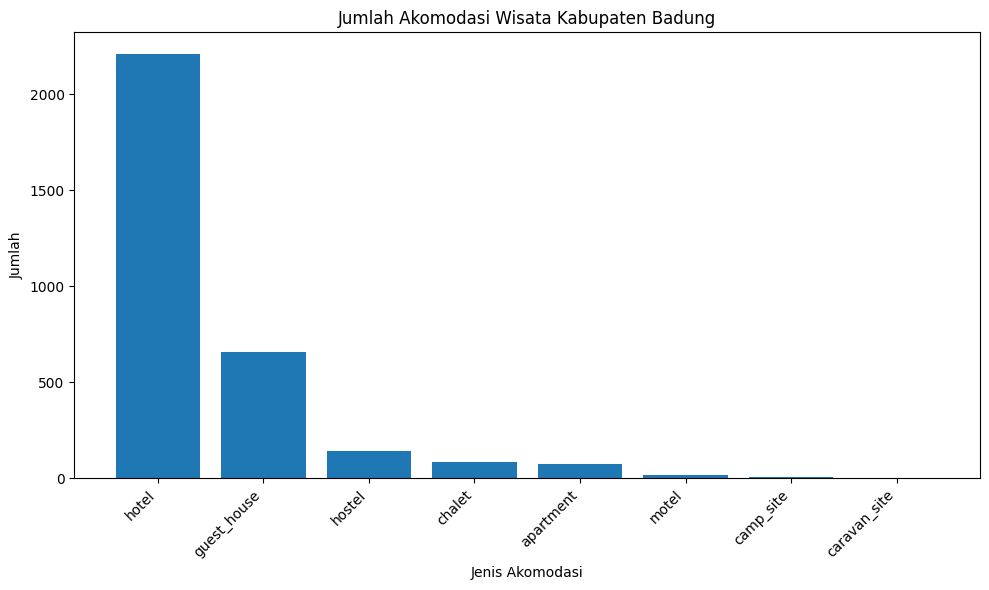

In [ ]:

# Menghitung jumlah setiap jenis akomodasi
jumlah_per_jenis = (
    df_clean["jenis_akomodasi"]
    .value_counts()
    .rename_axis("jenis_akomodasi")
    .reset_index(name="jumlah")
)

print("Jumlah Akomodasi Berdasarkan Jenis:")
display(jumlah_per_jenis)

# Membuat visualisasi grafik
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    jumlah_per_jenis["jenis_akomodasi"],
    jumlah_per_jenis["jumlah"]
)

plt.title("Jumlah Akomodasi Wisata Kabupaten Badung")
plt.xlabel("Jenis Akomodasi")
plt.ylabel("Jumlah")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()


In [ ]:

# Menghitung kelengkapan informasi
kolom_diperiksa = [
    "nama",
    "alamat",
    "kecamatan",
    "kabupaten",
    "telepon",
    "website"
]

hasil_kelengkapan = pd.DataFrame({
    "Kolom": kolom_diperiksa,
    "Data Terisi": [
        df_clean[k].notna().sum()
        for k in kolom_diperiksa
    ],
    "Data Kosong": [
        df_clean[k].isna().sum()
        for k in kolom_diperiksa
    ]
})

hasil_kelengkapan["Persentase Terisi (%)"] = (
    hasil_kelengkapan["Data Terisi"]
    / len(df_clean) * 100
).round(2)

print("Analisis Kelengkapan Data:")
display(hasil_kelengkapan)


Analisis Kelengkapan Data:


,Kolom,Data Terisi,Data Kosong,Persentase Terisi (%)
0,nama,2641,554,82.66
1,alamat,922,2273,28.86
2,kecamatan,62,3133,1.94
3,kabupaten,1,3194,0.03
4,telepon,613,2582,19.19
5,website,407,2788,12.74


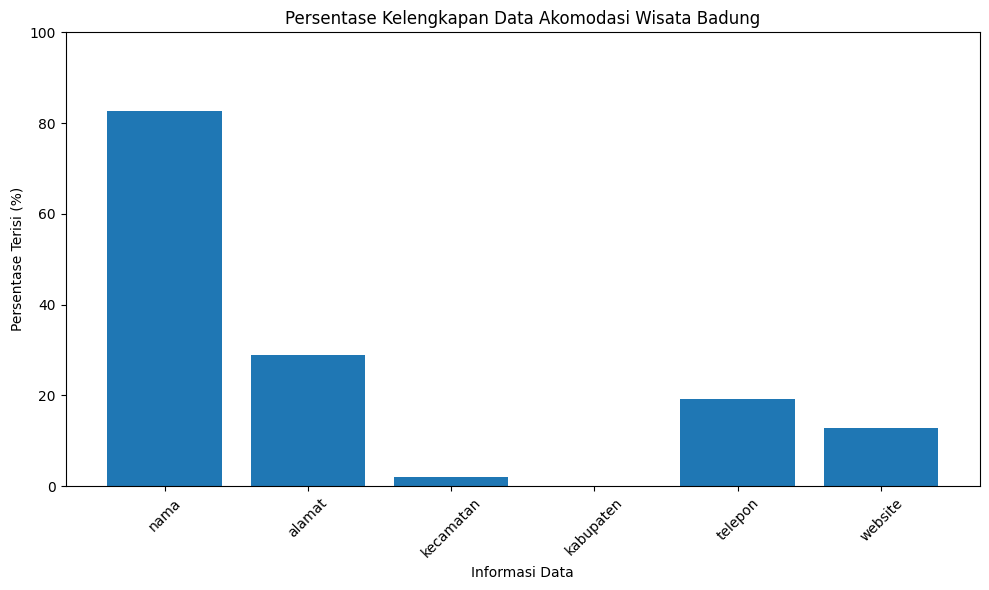

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    hasil_kelengkapan["Kolom"],
    hasil_kelengkapan["Persentase Terisi (%)"]
)

plt.title("Persentase Kelengkapan Data Akomodasi Wisata Badung")
plt.xlabel("Informasi Data")
plt.ylabel("Persentase Terisi (%)")

plt.ylim(0, 100)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [ ]:

import os

# Membuat folder untuk menyimpan hasil
folder_output = "/content/drive/MyDrive/rtm1_2501010203/data/processed"

os.makedirs(folder_output, exist_ok=True)

# Menyimpan dataset yang sudah dibersihkan
file_output = os.path.join(
    folder_output,
    "akomodasi_badung_clean.csv"
)

df_clean.to_csv(
    file_output,
    index=False,
    encoding="utf-8-sig"
)

# Memeriksa hasil penyimpanan
print("Dataset berhasil disimpan!")
print("Lokasi:", file_output)
print("Jumlah data:", len(df_clean))
print("Jumlah kolom:", len(df_clean.columns))
print("Ukuran file:", os.path.getsize(file_output), "bytes")


Dataset berhasil disimpan!
Lokasi: /content/drive/MyDrive/rtm1_2501010203/data/processed/akomodasi_badung_clean.csv
Jumlah data: 3195
Jumlah kolom: 11
Ukuran file: 254114 bytes


In [ ]:
import os

print("Tes Google Colab berhasil!")

# Menggunakan 'df' karena 'df_raw' tidak didefinisikan
print("Jumlah data raw:", len(df))
print("Jumlah data cleaning:", len(df_clean))

# Menggunakan 'ROOT' karena 'base_path' tidak didefinisikan
print("Folder proyek tersedia:", os.path.exists(ROOT))

Tes Google Colab berhasil!
Jumlah data raw: 3195
Jumlah data cleaning: 3195
Folder proyek tersedia: True
